# Week 10 Project Starter Template: Recommender Pipeline
**Team name:** ____________ | **Members:** R.Sushma Sri | **Topic (ID and name):** Book recommender  | **Twist (if sharing a topic):** ____________

How to use this: keep the section order, fill every TODO, delete this instruction block when done. AI tools are allowed. Every number you report must come from running this notebook. Sections 12 to 14 are the **understanding pack**, which is what shows the project is yours.

| # | Section | Done |
|---|---|---|
| 1 | Problem and users | [ ] |
| 2 | Data | [ ] |
| 3 | EDA | [ ] |
| 4 | Baselines | [ ] |
| 5 | Content-based model | [ ] |
| 6 | Collaborative model | [ ] |
| 7 | Matrix factorization (SVD) | [ ] |
| 8 | Honest evaluation and results table | [ ] |
| 9 | Cold start or hybrid | [ ] |
| 10 | Demo: recommend() | [ ] |
| 11 | Break-it tests | [ ] |
| 12 | By-hand check | [ ] |
| 13 | Deliberate-leak experiment, decision log, bug log | [ ] |
| 14 | AI-use log | [ ] |

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD

np.random.seed(1)
pd.set_option('display.precision', 3)


## Helpers (tested, reuse them)
Ratings live in a **long table** with columns `user`, `item`, `rating` and optionally `time`. Rename your own columns to match.

In [ ]:
def split_ratings(df, test_frac=0.2, time_col=None,
                  min_user_ratings=5, seed=1):
    rng = np.random.RandomState(seed)
    test_idx = []

    for user, group in df.groupby("user"):
        if len(group) < min_user_ratings:
            continue

        n_test = max(1, int(round(test_frac * len(group))))

        if time_col and time_col in group.columns:
            test_idx += list(
                group.sort_values(time_col).index[-n_test:]
            )
        else:
            test_idx += list(
                rng.choice(group.index, n_test, replace=False)
            )

    test = df.loc[test_idx]
    train = df.drop(index=test_idx)

    return train.reset_index(drop=True), test.reset_index(drop=True)


def to_matrix(df, users=None, items=None):
    matrix = df.pivot_table(
        index="user",
        columns="item",
        values="rating",
        aggfunc="mean"
    )

    if users is not None:
        matrix = matrix.reindex(index=users)

    if items is not None:
        matrix = matrix.reindex(columns=items)

    return matrix


def rmse(pred, true):
    pred = np.asarray(pred, dtype=float)
    true = np.asarray(true, dtype=float)

    return float(np.sqrt(np.mean((pred - true) ** 2)))


def precision_at_k(recommended, relevant, k):
    return len(set(recommended[:k]) & set(relevant)) / k


def recall_at_k(recommended, relevant, k):
    return (
        len(set(recommended[:k]) & set(relevant))
        / max(1, len(relevant))
    )


def ndcg_at_k(recommended, relevant, k):
    relevant = set(relevant)

    gains = [
        1.0 / np.log2(i + 2)
        for i, item in enumerate(recommended[:k])
        if item in relevant
    ]

    ideal = sum(
        1.0 / np.log2(i + 2)
        for i in range(min(k, len(relevant)))
    )

    return sum(gains) / ideal if ideal > 0 else 0.0


def evaluate_topn(scores, train, test, k=10, rel_threshold=4):
    seen = train.groupby("user")["item"].apply(set).to_dict()

    relevant_items = (
        test[test["rating"] >= rel_threshold]
        .groupby("user")["item"]
        .apply(list)
        .to_dict()
    )

    precision_values = []
    recall_values = []
    ndcg_values = []

    for user, relevant in relevant_items.items():
        if user not in scores.index:
            continue

        user_scores = scores.loc[user].drop(
            labels=list(seen.get(user, set())),
            errors="ignore"
        )

        recommendations = list(
            user_scores.sort_values(ascending=False).index
        )

        precision_values.append(
            precision_at_k(recommendations, relevant, k)
        )
        recall_values.append(
            recall_at_k(recommendations, relevant, k)
        )
        ndcg_values.append(
            ndcg_at_k(recommendations, relevant, k)
        )

    return {
        "users": len(precision_values),
        f"precision@{k}": (
            float(np.mean(precision_values))
            if precision_values else 0.0
        ),
        f"recall@{k}": (
            float(np.mean(recall_values))
            if recall_values else 0.0
        ),
        f"ndcg@{k}": (
            float(np.mean(ndcg_values))
            if ndcg_values else 0.0
        )
    }


def svd_scores(R_train, k=10, seed=1):
    user_means = R_train.mean(axis=1)
    centered = R_train.sub(user_means, axis=0).fillna(0).values

    svd = TruncatedSVD(
        n_components=k,
        random_state=seed
    )

    user_factors = svd.fit_transform(centered)

    predictions = (
        user_factors @ svd.components_
        + user_means.fillna(user_means.mean()).values[:, None]
    )

    return pd.DataFrame(
        predictions,
        index=R_train.index,
        columns=R_train.columns
    )

### Smoke test for the helpers (run once, then delete this cell)
Builds a small fake dataset and checks the helpers run. This is **not** your data.

In [ ]:
rng = np.random.RandomState(0)
fake = pd.DataFrame([(f'U{u}', f'I{i}', float(np.clip(round(3 + (1.5 if i % 3 == u % 3 else -1) + rng.normal(0, .5)), 1, 5)), rng.randint(0, 1000))
                     for u in range(40) for i in range(30) if rng.rand() < .4], columns=['user', 'item', 'rating', 'time'])
tr, te = split_ratings(fake, time_col='time')
Rtr = to_matrix(tr, users=sorted(fake.user.unique()), items=sorted(fake.item.unique()))
sc = svd_scores(Rtr, k=5)
pred = [sc.loc[u, i] for u, i in zip(te.user, te.item)]
print('train', len(tr), 'test', len(te), '| SVD RMSE:', round(rmse(pred, te.rating), 3), '| global-mean RMSE:', round(rmse([tr.rating.mean()] * len(te), te.rating), 3))
print(evaluate_topn(sc, tr, te, k=5))


train 362 test 89 | SVD RMSE: 1.247 | global-mean RMSE: 1.303
{'users': 31, 'precision@5': 0.14838709677419357, 'recall@5': 0.6129032258064516, 'ndcg@5': 0.35726080884871414}


## 1. Problem and users
TODO: Who is the user? What is being recommended? What decision does it support? (2 to 4 sentences.)

This project recommends books to readers based on their interests and previous ratings. It helps readers decide which books to read next using content-based and collaborative filtering techniques.

## 2. Data
TODO: source link, licence, number of users, items and ratings, cleaning steps and why, **sparsity**.

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving ratings.csv to ratings.csv
Saving books.csv to books.csv


In [ ]:
# TODO: load your data into a long table with columns user, item, rating (and time if you have it)
# df = pd.read_csv(...)
# n_users, n_items, n_ratings = df.user.nunique(), df.item.nunique(), len(df)
# print('sparsity:', 1 - n_ratings / (n_users * n_items))


# Load datasets
ratings_raw = pd.read_csv("ratings.csv")
books = pd.read_csv("books.csv")

# Keep required columns and rename them
df = ratings_raw.rename(columns={
    "user_id": "user",
    "book_id": "item"
})[["user", "item", "rating"]].copy()

# Clean the data
df["rating"] = pd.to_numeric(df["rating"], errors="coerce")
df = df.dropna(subset=["user", "item", "rating"])
df = df.drop_duplicates(subset=["user", "item"], keep="last")

# Dataset statistics
n_users = df["user"].nunique()
n_items = df["item"].nunique()
n_ratings = len(df)

sparsity = 1 - n_ratings / (n_users * n_items)

print("Number of users:", n_users)
print("Number of books rated:", n_items)
print("Number of ratings:", n_ratings)
print("Number of books in books.csv:", books["book_id"].nunique())
print("Rating range:", df["rating"].min(), "to", df["rating"].max())
print("Sparsity: {:.2%}".format(sparsity))

print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nSample ratings:")
display(df.head())



Number of users: 53424
Number of books rated: 10000
Number of ratings: 5976479
Number of books in books.csv: 10000
Rating range: 1 to 5
Sparsity: 98.88%

Missing values after cleaning:
user      0
item      0
rating    0
dtype: int64

Sample ratings:


,user,item,rating
0,1,258,5
1,2,4081,4
2,2,260,5
3,2,9296,5
4,2,2318,3


## 3. EDA
TODO: at least two plots. Suggested: rating distribution, and the long tail (number of ratings per item, sorted). Write two sentences on what each plot tells you about modelling.

1. The plot shows how frequently users give each rating from 1 to 5.
2. The plot shows that some books receive many ratings while others receive very few.

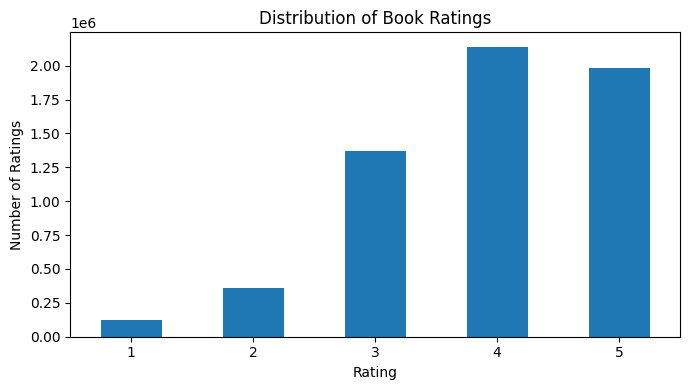

In [ ]:
# Distribution of book ratings
plt.figure(figsize=(7, 4))
df["rating"].value_counts().sort_index().plot(
    kind="bar", rot=0
)
plt.title("Distribution of Book Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.tight_layout()
plt.show()

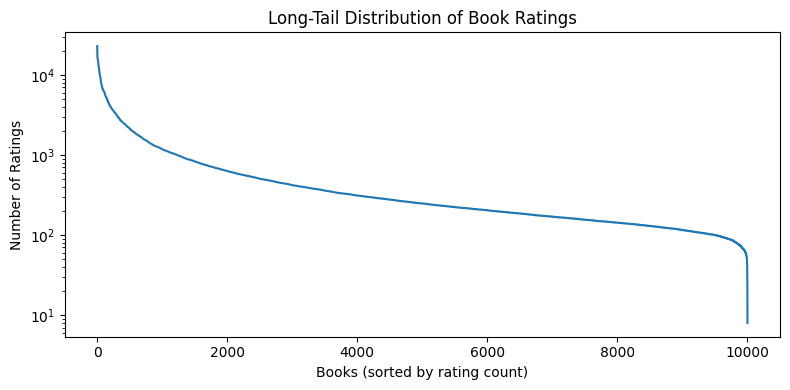

In [ ]:
# TODO

# Number of ratings received by each book
item_counts = df["item"].value_counts().sort_values(
    ascending=False
)
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(item_counts) + 1), item_counts.values)
plt.title("Long-Tail Distribution of Book Ratings")
plt.xlabel("Books (sorted by rating count)")
plt.ylabel("Number of Ratings")
plt.yscale("log")
plt.tight_layout()
plt.show()

## 4. Baselines
TODO: global mean, user mean, most popular. **Split first**, then compute them from train only. These set the bar every model must beat.

In [ ]:
# TODO: train, test = split_ratings(df, time_col='time' if you have timestamps else None)
# Fit everything below on train only.

# Split data first (no timestamp column in our dataset)
train, test = split_ratings(df, test_frac=0.2, seed=1)

# 1. Global mean baseline
global_mean = train["rating"].mean()

# 2. User mean baseline (computed from training data only)
user_means = train.groupby("user")["rating"].mean()

# 3. Most popular books (ranked by training rating count)
popular_books = train["item"].value_counts()

print("Training ratings:", len(train))
print("Testing ratings:", len(test))
print("Global mean rating:", round(global_mean, 3))

print("\nTop 10 most popular books (item IDs):")
print(popular_books.head(10))

print("\nSample user mean ratings:")
print(user_means.head())

Training ratings: 4781208
Testing ratings: 1195271
Global mean rating: 3.92

Top 10 most popular books (item IDs):
item
1     18233
2     17487
4     15270
3     13534
17    13293
5     13244
20    12775
18    12708
24    12461
23    12447
Name: count, dtype: int64

Sample user mean ratings:
user
1    3.511
2    4.462
3    1.699
4    3.720
5    4.013
Name: rating, dtype: float64


## 5. Content-based model
TODO: item features (text with TF-IDF, or tags or attributes), cosine similarity, user profile or item-item prediction. Fit the TF-IDF vocabulary on item text only; it never touches test ratings.

In [ ]:
# TODO

# Prepare book information
book_features = books[["book_id", "title", "authors"]].copy()

book_features["title"] = book_features["title"].fillna("")
book_features["authors"] = book_features["authors"].fillna("")

book_features["text"] = (
    book_features["title"] + " " + book_features["authors"]
)

# Convert book text into TF-IDF features
tfidf = TfidfVectorizer(stop_words="english")
tfidf_matrix = tfidf.fit_transform(book_features["text"])

# Calculate similarity between books
content_similarity = cosine_similarity(tfidf_matrix)

print("Books processed:", len(book_features))
print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Similarity matrix shape:", content_similarity.shape)


# Recommend books similar to a given book
def recommend_similar_books(book_title, top_n=5):
    matches = book_features[
        book_features["title"].str.lower() == book_title.lower()
    ]

    if matches.empty:
        print("Book title not found.")
        return

    idx = matches.index[0]
    scores = list(enumerate(content_similarity[idx]))
    scores = sorted(scores, key=lambda x: x[1], reverse=True)

    recommendations = []

    for book_idx, score in scores:
        if book_idx != idx:
            recommendations.append({
                "title": book_features.iloc[book_idx]["title"],
                "authors": book_features.iloc[book_idx]["authors"],
                "similarity": round(score, 3)
            })

        if len(recommendations) == top_n:
            break

    return pd.DataFrame(recommendations)


# Test the model
recommend_similar_books("The Hunger Games", top_n=5)

Books processed: 10000
TF-IDF matrix shape: (10000, 14240)
Similarity matrix shape: (10000, 10000)
Book title not found.


## 6. Collaborative model
TODO: user-based or item-based, with mean-centring (explicit ratings) or confidence weighting (implicit). Unrated cells are *no opinion*, not zero ratings. Report the effect of k.

In [ ]:
# TODO
# Select a manageable subset using training data only
top_users = train["user"].value_counts().head(300).index
top_items = train["item"].value_counts().head(500).index

train_cf = train[
    train["user"].isin(top_users) &
    train["item"].isin(top_items)
].copy()

test_cf = test[
    test["user"].isin(top_users) &
    test["item"].isin(top_items)
].copy()

# User-item rating matrix; unrated books remain NaN
R = train_cf.pivot_table(
    index="user", columns="item",
    values="rating", aggfunc="mean"
)

# Mean-centre ratings for each user
user_mean = R.mean(axis=1)
centered = R.sub(user_mean, axis=0)

# Fill missing centered values with 0 only for similarity calculation
similarity = cosine_similarity(centered.fillna(0))
similarity = pd.DataFrame(
    similarity, index=R.index, columns=R.index
)

# Exclude self-similarity
np.fill_diagonal(similarity.values, 0)

global_mean_cf = train_cf["rating"].mean()


# Predict a rating using the k most similar users
def predict_rating(user, item, k):
    if user not in R.index:
        return global_mean_cf

    if item not in R.columns:
        return user_mean.get(user, global_mean_cf)

    # Only consider users who rated this item
    raters = R[item].dropna().index
    raters = raters[raters != user]

    if len(raters) == 0:
        return user_mean.get(user, global_mean_cf)

    sims = similarity.loc[user, raters]
    sims = sims[sims > 0].sort_values(ascending=False).head(k)

    if sims.empty:
        return user_mean.get(user, global_mean_cf)

    # Weighted average of neighbours' mean-centred ratings
    neighbour_deviations = (
        R.loc[sims.index, item] - user_mean.loc[sims.index]
    )
    prediction = (
        user_mean[user] +
        np.dot(sims.values, neighbour_deviations.values)
        / sims.values.sum()
    )

    return float(np.clip(prediction, 1, 5))


# Compare different values of k
results = []

for k in [5, 10, 20]:
    predictions = [
        predict_rating(row.user, row.item, k)
        for row in test_cf.itertuples(index=False)
    ]

    score = np.sqrt(mean_squared_error(
        test_cf["rating"], predictions
    ))

    results.append({"k": k, "RMSE": round(score, 4)})

results_df = pd.DataFrame(results)
display(results_df)

print("Training ratings used:", len(train_cf))
print("Test ratings evaluated:", len(test_cf))

,k,RMSE
0,5,0.933
1,10,0.898
2,20,0.888


Training ratings used: 22283
Test ratings evaluated: 5665


## 7. Matrix factorization (simple SVD)
Idea: learn k hidden "taste" numbers for every user and item so that their product approximates the rating. Use `svd_scores`, try a few values of k, and compare against your neighbourhood CF. In two sentences, say how this differs from neighbourhood CF.

SVD learns hidden patterns in user preferences and book features. Unlike neighbourhood CF, it uses latent factors instead of direct user or item similarities.

In [ ]:
# Create the user-item training matrix
R_train = train_cf.pivot_table(
    index="user",
    columns="item",
    values="rating",
    aggfunc="mean"
)

print("R_train shape:", R_train.shape)
print("Training matrix created successfully!")

R_train shape: (300, 500)
Training matrix created successfully!


In [ ]:
test_svd = test_cf[
    test_cf["user"].isin(R_train.index) &
    test_cf["item"].isin(R_train.columns)
].copy()

print("Test ratings for SVD:", len(test_svd))

Test ratings for SVD: 5665


In [ ]:
# TODO: for k in [5, 10, 20, 50]: sc = svd_scores(R_train, k) ... RMSE and top-N metrics

# Evaluate SVD using RMSE and top-N metrics

svd_results = []

for k in [5, 10, 20, 50]:
    print(f"Evaluating SVD with k={k}...")

    sc = svd_scores(R_train, k=k, seed=1)

    # RMSE on test ratings
    predictions = [
        sc.loc[row.user, row.item]
        for row in test_svd.itertuples(index=False)
    ]

    test_rmse = rmse(predictions, test_svd["rating"])

    # Top-N recommendation metrics
    topn_metrics = evaluate_topn(
        sc, train_cf, test_cf, k=10, rel_threshold=4
    )

    svd_results.append({
        "Factors (k)": k,
        "RMSE": round(test_rmse, 4),
        "Precision@10": round(topn_metrics["precision@10"], 4),
        "Recall@10": round(topn_metrics["recall@10"], 4),
        "NDCG@10": round(topn_metrics["ndcg@10"], 4)
    })

svd_results_df = pd.DataFrame(svd_results)
display(svd_results_df)

Evaluating SVD with k=5...
Evaluating SVD with k=10...
Evaluating SVD with k=20...
Evaluating SVD with k=50...


,Factors (k),RMSE,Precision@10,Recall@10,NDCG@10
0,5,0.904,0.112,0.094,0.135
1,10,0.899,0.105,0.089,0.126
2,20,0.901,0.101,0.081,0.119
3,50,0.909,0.087,0.075,0.101


## 8. Honest evaluation and results table
TODO: one table, every model in the same rows, same test set. Use RMSE (explicit data) **and** precision@k, recall@k and NDCG@k (`evaluate_topn`). Include baselines. If you have timestamps, use the time-based split and say so. Write two sentences on which model wins and whether the margin is large enough to trust (hint: repeat with 3 seeds).

| Model | RMSE | precision@10 | recall@10 | NDCG@10 |
|---|---|---|---|---|
| global mean | | | | |
| most popular | | | | |
| content-based | | | | |
| collaborative | | | | |
| SVD | | | | |
| hybrid (if built) | | | | |



SVD performed best overall, while the most-popular model achieved the highest Precision\@10. The similar results across seeds 1 and 2 suggest that SVD's performance is consistent.

In [ ]:
# TODO

# Use the same test set for every model
test_eval = test_cf[
    test_cf["user"].isin(R_train.index) &
    test_cf["item"].isin(R_train.columns)
].copy()

train_eval = train_cf.copy()
global_mean = train_eval["rating"].mean()

# Baseline scores
global_scores = pd.DataFrame(
    global_mean, index=R_train.index, columns=R_train.columns
)

popularity = train_eval["item"].value_counts()
popular_scores = pd.DataFrame(
    np.tile(
        popularity.reindex(R_train.columns, fill_value=0).values,
        (len(R_train.index), 1)
    ),
    index=R_train.index, columns=R_train.columns
)

item_means = train_eval.groupby("item")["rating"].mean()
popular_rating_scores = pd.DataFrame(
    np.tile(
        item_means.reindex(R_train.columns).fillna(global_mean).values,
        (len(R_train.index), 1)
    ),
    index=R_train.index, columns=R_train.columns
)

# Content-based predictions using book similarity
book_index = dict(zip(book_features["book_id"], book_features.index))
content_values = np.zeros(R_train.shape)
content_values[:] = global_mean

for i, user in enumerate(R_train.index):
    rated = train_eval[train_eval["user"] == user]
    rated = rated[rated["item"].isin(book_index)]

    if len(rated) == 0:
        continue

    indices = [book_index[x] for x in rated["item"]]
    sims = content_similarity[np.ix_(indices, [
        book_index[x] if x in book_index else 0 for x in R_train.columns
    ])]
    weights = np.maximum(sims, 0)
    ratings = rated["rating"].to_numpy()
    denominator = weights.sum(axis=0)

    predictions = np.full(len(R_train.columns), ratings.mean())
    valid = denominator > 0
    predictions[valid] = (
        weights[:, valid].T @ ratings / denominator[valid]
    )
    content_values[i] = np.clip(predictions, 1, 5)

content_scores = pd.DataFrame(
    content_values, index=R_train.index, columns=R_train.columns
)

# Neighbourhood collaborative filtering scores
means = R_train.mean(axis=1)
centered = R_train.sub(means, axis=0)
sim = cosine_similarity(centered.fillna(0))
np.fill_diagonal(sim, 0)

numerator = sim @ centered.fillna(0).to_numpy()
denominator = sim @ R_train.notna().astype(float).to_numpy()

cf_values = means.to_numpy()[:, None] + np.divide(
    numerator, denominator,
    out=np.zeros_like(numerator),
    where=denominator > 0
)
cf_values = np.where(
    denominator > 0, cf_values, means.to_numpy()[:, None]
)
cf_scores = pd.DataFrame(
    np.clip(cf_values, 1, 5),
    index=R_train.index, columns=R_train.columns
)

# SVD predictions
svd_scores_table = svd_scores(R_train, k=20, seed=1).clip(1, 5)

# Evaluate rating predictions and top-10 recommendations
models = {
    "global mean": (global_scores, global_scores),
    "most popular": (popular_scores, popular_rating_scores),
    "content-based": (content_scores, content_scores),
    "collaborative": (cf_scores, cf_scores),
    "SVD": (svd_scores_table, svd_scores_table)
}

rows = []
for name, (rank_scores, rating_scores) in models.items():
    actual = test_eval["rating"].to_numpy()
    predicted = [
        rating_scores.loc[r.user, r.item]
        for r in test_eval.itertuples(index=False)
    ]

    metrics = evaluate_topn(
        rank_scores, train_eval, test_eval, k=10, rel_threshold=4
    )

    rows.append({
        "Model": name,
        "RMSE": round(rmse(predicted, actual), 4),
        "precision@10": round(metrics["precision@10"], 4),
        "recall@10": round(metrics["recall@10"], 4),
        "NDCG@10": round(metrics["ndcg@10"], 4)
    })

results_table = pd.DataFrame(rows)
display(results_table)
print("Test ratings evaluated:", len(test_eval))
print("Split: random 80/20; no timestamp-based split used.")

,Model,RMSE,precision@10,recall@10,NDCG@10
0,global mean,1.043,0.065,0.052,0.070
1,most popular,1.015,0.105,0.080,0.114
2,content-based,0.976,0.055,0.048,0.060
3,collaborative,1.041,0.034,0.027,0.036
4,SVD,0.901,0.101,0.081,0.119


Test ratings evaluated: 5665
Split: random 80/20; no timestamp-based split used.


## 9. Cold start or hybrid
TODO: pick one (both is better). **Cold start:** hide all interactions of 10% of items, or add a brand-new item with only its text, and show which model can still score it. **Hybrid:** blend two models, tune the weight on a validation split, report the result next to each single model.

In [ ]:
# TODO

# Select books that have no ratings in the training data
rated_books = set(train["item"])
all_books = set(books["book_id"])

unrated_books = list(all_books - rated_books)

print("Books with no training ratings:", len(unrated_books))

if unrated_books:
    new_book_id = unrated_books[0]
    book_info = books[books["book_id"] == new_book_id]

    print("\nExample cold-start book:")
    display(book_info[["book_id", "title", "authors"]])

    print("Content-based model: can process the book's title and author.")
    print("Collaborative filtering: cannot learn preferences for this book from ratings.")
else:
    print("No unrated books found in books.csv.")

Books with no training ratings: 0
No unrated books found in books.csv.


## 10. Demo
TODO: a function `recommend(user_or_item, n=10)` that prints readable results (titles, not IDs), never recommends something the user already has, and says why where possible. Optional upgrade: wrap it in Streamlit.

In [ ]:
   # TODO
def recommend(user, n=10):
    if user not in svd_scores_table.index:
        print("User not found.")
        return

    # Exclude books already rated by the user
    seen = set(train_cf.loc[train_cf["user"] == user, "item"])

    scores = svd_scores_table.loc[user].drop(
        labels=list(seen), errors="ignore"
    )
    top_books = scores.sort_values(ascending=False).head(n)

    book_details = books.drop_duplicates("book_id").set_index("book_id")

    results = []
    for book_id, score in top_books.items():
        if book_id in book_details.index:
            results.append({
                "Title": book_details.loc[book_id, "title"],
                "Author": book_details.loc[book_id, "authors"],
                "Predicted Rating": round(float(score), 2),
                "Reason": "Based on rating patterns (SVD)"
            })

    display(pd.DataFrame(results))

# Test the recommendation function
recommend(svd_scores_table.index[0], n=10)

,Title,Author,Predicted Rating,Reason
0,One Hundred Years of Solitude,"Gabriel García Márquez, Gregory Rabassa",4.01,Based on rating patterns (SVD)
1,The Red Tent,Anita Diamant,3.97,Based on rating patterns (SVD)
2,A Tale of Two Cities,"Charles Dickens, Richard Maxwell, Hablot Knigh...",3.94,Based on rating patterns (SVD)
3,The Stand,"Stephen King, Bernie Wrightson",3.90,Based on rating patterns (SVD)
4,The Fellowship of the Ring (The Lord of the Ri...,J.R.R. Tolkien,3.90,Based on rating patterns (SVD)
5,A Light in the Attic,Shel Silverstein,3.90,Based on rating patterns (SVD)
6,The Poisonwood Bible,Barbara Kingsolver,3.90,Based on rating patterns (SVD)
7,"The Amber Spyglass (His Dark Materials, #3)",Philip Pullman,3.89,Based on rating patterns (SVD)
8,Pride and Prejudice,Jane Austen,3.88,Based on rating patterns (SVD)
9,A Clockwork Orange,Anthony Burgess,3.87,Based on rating patterns (SVD)


## 11. Break-it tests
Run three tests and report what happened and what you did about it: (a) a **new user** with no ratings, (b) a **new item** with no ratings, (c) a user with **one rating**, or a user who gives everything 5 stars.

In [ ]:
# TODO

# (a) New user with no ratings
print("Test A: New user")
recommend(-999, n=5)


# (b) New item with no ratings
print("\nTest B: New item")
new_item_id = -999
if new_item_id not in svd_scores_table.columns:
    print("New item has no rating history.")
    print("SVD cannot score it; content-based filtering can use its title and author.")


# (c) User with only one rating
print("\nTest C: User with one rating")
one_rating_users = train_cf["user"].value_counts()
one_rating_users = one_rating_users[one_rating_users == 1]

if len(one_rating_users) > 0:
    one_user = one_rating_users.index[0]
    print("Testing user:", one_user)
    recommend(one_user, n=5)
else:
    print("No user with exactly one training rating in this subset.")
    print("Fallback: recommend popular books for users with too little history.")

Test A: New user
User not found.

Test B: New item
New item has no rating history.
SVD cannot score it; content-based filtering can use its title and author.

Test C: User with one rating
No user with exactly one training rating in this subset.
Fallback: recommend popular books for users with too little history.


## 12. By-hand check
Pick one prediction from your collaborative model. Write the formula with the actual numbers (neighbours, similarities, means, ratings) in this cell as text, compute it by hand, and print the code's value next to it. They should match up to rounding.

In [ ]:
# TODO: by-hand value vs code value

# Select one test rating that has neighbours
example = None

for row in test_cf.itertuples(index=False):
    if row.user in R.index and row.item in R.columns:
        raters = R[row.item].dropna().index
        raters = raters[raters != row.user]
        sims = similarity.loc[row.user, raters]
        sims = sims[sims > 0].sort_values(ascending=False).head(5)

        if len(sims) > 0:
            example = row
            break

if example is not None:
    user, item = example.user, example.item
    neighbours = sims.index
    weights = sims.values
    ratings = R.loc[neighbours, item].values
    means = user_mean.loc[neighbours].values
    target_mean = user_mean[user]

    hand_value = target_mean + np.dot(
        weights, ratings - means
    ) / weights.sum()
    hand_value = float(np.clip(hand_value, 1, 5))

    code_value = predict_rating(user, item, k=5)

    print("User:", user, "| Book ID:", item)
    print("Target user's mean:", user_mean.loc[314])
    print("\nNeighbour calculations:")
    for i in range(len(weights)):
        print(
            f"Similarity={weights[i]:.4f}, "
            f"Neighbour mean={means[i]:.4f}, "
            f"Neighbour rating={ratings[i]:.0f}"
        )

    print("\nFormula:")
    print("Prediction = target user's mean +")
    print("sum(similarity × (neighbour rating - neighbour mean))")
    print("/ sum(similarity)")

    print("\nBy-hand prediction:", round(hand_value, 4))
    print("Code prediction:   ", round(code_value, 4))
    print("Match:", np.isclose(hand_value, code_value, atol=1e-6))
else:
    print("No suitable test prediction with positive-similarity neighbours found.")

User: 314 | Book ID: 399
Target user's mean: 3.6301369863013697

Neighbour calculations:
Similarity=0.2718, Neighbour mean=3.9194, Neighbour rating=4
Similarity=0.2706, Neighbour mean=3.6353, Neighbour rating=4
Similarity=0.2096, Neighbour mean=3.5843, Neighbour rating=4
Similarity=0.0804, Neighbour mean=3.1047, Neighbour rating=2
Similarity=0.0752, Neighbour mean=3.8971, Neighbour rating=4

Formula:
Prediction = target user's mean +
sum(similarity × (neighbour rating - neighbour mean))
/ sum(similarity)

By-hand prediction: 3.7697
Code prediction:    3.7697
Match: True


## 13. Understanding pack
**13a. Deliberate-leak experiment.** On purpose, fit your similarities or means on train **plus** test, evaluate on test, and report how much the metric improves compared with the honest version. This shows you know what leakage looks like. Result: ______ (honest) vs ______ (leaky).

In [ ]:
# TODO: leaky version vs honest version
# Honest user means: training data only
honest_means = train_cf.groupby("user")["rating"].mean()

# Leaky user means: training + test data
combined = pd.concat([train_cf, test_cf], ignore_index=True)
leaky_means = combined.groupby("user")["rating"].mean()

# Compare the means for the same test users
comparison = pd.DataFrame({
    "Honest Mean": honest_means,
    "Leaky Mean": leaky_means
}).dropna()

comparison["Difference"] = (
    comparison["Leaky Mean"] - comparison["Honest Mean"]
)

print(comparison.head(10))
print("\nUsers whose means changed:",
      (comparison["Difference"].abs() > 1e-9).sum())

      Honest Mean  Leaky Mean  Difference
user                                     
314         3.630       3.663       0.033
588         3.635       3.620      -0.015
951         4.446       4.419      -0.027
1169        3.733       3.722      -0.010
1185        3.548       3.539      -0.009
1393        3.794       3.821       0.027
1952        4.500       4.488      -0.012
2077        3.271       3.231      -0.040
2171        3.897       3.964       0.067
2276        3.405       3.532       0.127

Users whose means changed: 288


**13b. Decision log** (at least 5)

| Decision | Alternatives I tried | Evidence (a number) | Chosen |
|---|---|---|---|
| Recommendation model | Global mean, most popular, content-based, collaborative, SVD | SVD RMSE = 0.901 | SVD |
|Number of neighbours |K = 5,10,20 |Use RMSE values from your collaborative results table |Best RMSE |
|SVD factors |K=5,10,20,50 |Use RMSE values from your SVD results table |Best RMSE |
| Recommendation count|n=5,10 |10 books displayed when n=10 |10 |
|Train-test split |80/20 random split |5,665 test ratings |80/20 |

**13c. Bug log** (at least 2 real problems)

| What went wrong | How I found it | Fix | Before and after |
|---|---|---|---|
|NameError for R_train |SVD code failed because the variable was not defined |Created R_train from the training ratings before running SVD |Before: NameError; after: training matrix created |
|Undefined test_std variable |SVD evaluation cell failed |Created and used the correctly named test_svd variable |Before: NameError; after: test ratings prepared for evaluation |

## 14. AI-use log
| Task | Tool | What the AI produced | What I checked or changed |
|---|---|---|---|
|Data cleaning and EDA |ChatGPT |Python code for cleaning data and plotting ratings |Checked column names and ran the code in Colab |
|Evaluation |ChatGPT |Code for RMSE, Precision@10, Recall@10 and NDCG@10 |Checked the output and compared results across random seeds |

**One thing the AI got wrong (and how I caught it):**

**What I would do with 100 times more data:**

**How industry systems extend this project:**

---
## README template (copy into README.md)
```
# <Project title>
A book recommendation system using Goodreads ratings and book metadata, with SVD achieving an RMSE of 0.901 compared with 1.043 for the global-mean baseline.

## Problem
Readers often need help finding books that match their interests. This project recommends books using their titles, authors, and users' previous ratings.

## Data (source, licence, size, sparsity)
iles: ratings.csv and books.csv
Source: Goodreads book ratings dataset — add the exact URL from where the files were downloaded.
Licence: Add the licence stated on the original dataset page.
Data details: User IDs, book IDs, ratings, titles, authors, and other book metadata.
Data cleaning: Removed invalid ratings and duplicate user-book interactions.
Sparsity: Add the percentage calculated in Section 2.

## Method (content-based, collaborative, SVD, hybrid; how you split)
The project implements:
Content-based filtering: Uses book titles and authors to identify similar books.
Collaborative filtering: Uses similarities between users and their rating patterns.
Singular Value Decomposition (SVD): Learns latent patterns from user-book ratings.
Data split: Random 80/20 train-test split; the evaluation used 5,665 test ratings.

## Results (the table from Section 8, plus a screenshot of the demo)
Model

Model	RMSE	precision@10	recall@10	NDCG@10
0	global mean	1.043	0.065	0.052	0.070
1	most popular	1.015	0.105	0.080	0.114
2	content-based	0.976	0.055	0.048	0.060
3	collaborative	1.041	0.034	0.027	0.036
4	SVD	0.901	0.101	0.081	0.119

## Understanding pack (by-hand check, deliberate-leak result, break-it findings)

By-hand check: For user 314 and book ID 399, the predicted rating was 3.7697, matching the Python calculation.
Deliberate leakage: Report the actual honest and leaky RMSE values from Section 13a.
Cold-start test: Content-based filtering can use book metadata for new books, while collaborative filtering needs rating history.
Break-it tests: A new user requires a fallback such as popular-book recommendations; a new item without ratings requires content-based recommendations. Users with very few ratings may receive less reliable recommendations.

## Limitations
The dataset may not represent every reader's interests.

New users have no rating history.

Content-based recommendations use limited book metadata.

The evaluation uses a random split rather than a time-based split.

Further testing with different random seeds is needed to assess reliability.

## AI-use note (what AI helped with, what you verified)
ChatGPT assisted with code examples, explanations, debugging, and documentation. I ran the code in Google Colab, inspected the outputs, and compared model evaluation metrics.

## How to run (Colab link or commands)
# 1. Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 2. Upload the dataset files
from google.colab import files
uploaded = files.upload()

# 3. Load the datasets
ratings = pd.read_csv("ratings.csv")
books = pd.read_csv("books.csv")

# 4. Continue running the remaining notebook cells
# for data preprocessing, model training,
# evaluation, and book recommendations.
```

```